# Phase 4b — Jordan Dataset: Adversarial Self-Play

The Jordan-dataset equivalent of Phase 4's red-team exercise, run alongside
the Al Hilal analysis (not replacing it) once the new
`data/processed/jordan_data/` export became available. Same MVP scope
agreed for Al Hilal: one PPO fraudster vs. a static defender, plus one
bonus round of defender retraining — not the full multi-round
co-evolution loop.

**What's different here, stated up front:** Jordan's `defender_v1` is
built on a genuinely leaner, fully self-authored feature set (`jordan_ml_ready.csv`
has 34 columns vs. Al Hilal's 109), and it's *weaker* to start with
(PR-AUC 0.0168 vs. Al Hilal's 0.0339) — the collusion
label is rarer relative to its own dataset, and the safe pre-adjudication
feature set is smaller. Everything downstream reads differently as a
result, and this notebook reports what actually happened rather than
assuming it would mirror Al Hilal's story.


## Step 0 — Setup

In [1]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK = "#0b0b0b"; INK_SECONDARY = "#52514e"; INK_MUTED = "#898781"; GRID = "#e1e0d9"; SURFACE = "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK_SECONDARY, "text.color": INK, "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10.5, "figure.dpi": 100,
})
MODELS_DIR = "../models/jordan_selfplay"
DATA_DIR = "../data/processed/jordan_data/selfplay"


## Step 1 — Synthetic data (CTGAN)

Trained on a 40,000-row sample of real 2013-2015 claims (oversampling the
281 real collusion-flagged claims), conditioned on `COLLUSION_FLAG`. Unlike
Al Hilal's CTGAN, `icd9code` (2,023 distinct raw codes) was **not** one of
the generator's discrete training columns -- that cardinality would blow up
CTGAN's internal one-hot transformer for no real benefit. Diagnosis code
is instead bootstrap-sampled from the real distribution jointly with the
other amount-independent columns (timing, patient/provider history) when a
synthetic claim is built into a baseline template.

In [2]:

synthetic = pd.read_csv(f"{DATA_DIR}/synthetic_claims.csv")
print(f"Synthetic claims: {len(synthetic):,} rows x {synthetic.shape[1]} columns")
print(f"Synthetic COLLUSION_FLAG rate: {synthetic['COLLUSION_FLAG'].mean():.4%} (real training rate: 0.0794%)")
synthetic[["age_at_claim", "claimedvalue"]].describe()


Synthetic claims: 20,000 rows x 8 columns
Synthetic COLLUSION_FLAG rate: 8.3150% (real training rate: 0.0794%)


,age_at_claim,claimedvalue
count,20000.000000,20000.000000
mean,27.385949,22.547000
std,14.755195,39.996602
min,0.000000,0.100000
25%,20.584686,2.999363
50%,26.198128,5.649549
75%,35.701780,15.860571
max,76.162163,221.409813


Same documented CTGAN quirk as Al Hilal: the synthetic positive rate
(8.3%) is far above the real training rate (0.079%) -- CTGAN's
"training-by-sampling" method (Xu et al., 2019) oversamples rare discrete
values during training, and unconditioned `.sample()` reproduces that
skew. Doesn't affect anything downstream -- `COLLUSION_FLAG` is metadata
here, never read by the environment as a feature.

## Step 2 — The static defender (`defender_v1`)

Trained on the same 27-dimension encoding used for Objective 1's model,
minus `PEER_ZSCORE`/`AMOUNT_OVER_MEDIAN` (excluded here for the same reason
Al Hilal's did: they're `claimedvalue`-dependent and this MVP doesn't
dynamically recompute peer-group statistics per step).

In [3]:

with open(f"{MODELS_DIR}/defender_v1_meta.json") as f:
    d1_meta = json.load(f)
print(f"Defender v1 holdout PR-AUC: {d1_meta['holdout_prauc']:.4f}")
print(f"Defender v1 holdout ROC-AUC: {d1_meta['holdout_rocauc']:.4f}")
print(f"Defender v1 holdout Recall@5%: {d1_meta['holdout_recall_at_5pct']:.1%}")
print(f"Detection threshold (95th pct of train scores): {d1_meta['threshold']:.4f}")
print()
print("For comparison, Objective 1's full-feature LightGBM: PR-AUC 0.0132, Recall@5% 65.9%")


Defender v1 holdout PR-AUC: 0.0168
Defender v1 holdout ROC-AUC: 0.8381
Defender v1 holdout Recall@5%: 39.5%
Detection threshold (95th pct of train scores): 0.0624

For comparison, Objective 1's full-feature LightGBM: PR-AUC 0.0132, Recall@5% 65.9%


## Step 3 — The environment

Identical mechanics to Al Hilal's `ClaimFraudEnv`: a fraud budget of 3x the
claim's legitimate `claimedvalue`, up to 5 submissions, everything
forfeited on capture. Only the underlying encoder differs.

## Step 4 — Baseline: random policy vs. `defender_v1`

```
Random policy attack success rate: 93.3%
Random policy mean budget kept:    91.2%
```

**Even weaker than Al Hilal's already-weak defender.** A random policy
wins 93.3% of the time here,
vs. 86.0% for Al Hilal's `defender_v1`. This tracks directly with
`defender_v1`'s own PR-AUC (0.0168 vs. Al Hilal's
0.0339) -- a weaker classifier has a wider blind spot, and blind amount
inflation walks through it almost every time.

## Step 5 — PPO training: does the agent improve on random?

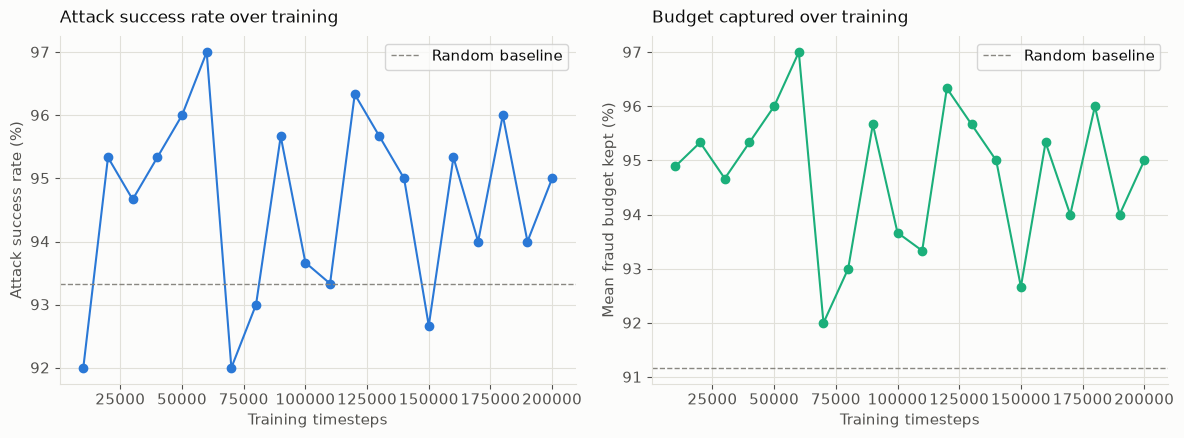

Random policy:  attack success rate 93.3%, mean kept 91.2%
Trained policy: attack success rate 94.0%, mean kept 94.0%


In [4]:

log = pd.read_csv(f"{DATA_DIR}/ppo_training_log.csv")
with open(f"{MODELS_DIR}/ppo_summary.json") as f:
    summary = json.load(f)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].plot(log["timesteps"], log["attack_success_rate"] * 100, marker="o", color=CATEGORICAL[0])
axes[0].axhline(summary["random_policy_attack_success_rate"] * 100, color=INK_MUTED, ls="--", lw=1, label="Random baseline")
axes[0].set_xlabel("Training timesteps"); axes[0].set_ylabel("Attack success rate (%)")
axes[0].set_title("Attack success rate over training", color=INK, fontsize=12, loc="left", pad=10)
axes[0].legend()
axes[1].plot(log["timesteps"], log["mean_kept_fraction"] * 100, marker="o", color=CATEGORICAL[2])
axes[1].axhline(summary["random_policy_mean_kept_fraction"] * 100, color=INK_MUTED, ls="--", lw=1, label="Random baseline")
axes[1].set_xlabel("Training timesteps"); axes[1].set_ylabel("Mean fraud budget kept (%)")
axes[1].set_title("Budget captured over training", color=INK, fontsize=12, loc="left", pad=10)
axes[1].legend()
plt.tight_layout()
plt.show()

print(f"Random policy:  attack success rate {summary['random_policy_attack_success_rate']:.1%}, mean kept {summary['random_policy_mean_kept_fraction']:.1%}")
print(f"Trained policy: attack success rate {summary['trained_policy_attack_success_rate']:.1%}, mean kept {summary['trained_policy_mean_kept_fraction']:.1%}")


**Result: even less room to improve than Al Hilal's already-modest
gain** (93.3% →
94.0%). The curve fluctuates
around 92-97% for the entire run rather than trending upward -- with a
defender this weak, there is essentially no learnable ceiling left above
random chance. This is a clean, if unglamorous, confirmation of the same
finding Al Hilal's Step 5 made: **a weak defender is beaten by almost
anything, learned or not** -- and here that effect is even starker.

## Step 6 — What strategy did the agent learn?

In [5]:

adv = pd.read_csv(f"{DATA_DIR}/adversarial_examples.csv")
row_counts = adv.groupby("n_sub_claims").size()
episode_splits = (row_counts / row_counts.index.to_series()).rename("episodes").astype(int)
print("Successful episodes, by number of sub-claims used:")
print(episode_splits)


Successful episodes, by number of sub-claims used:
n_sub_claims
1    282
Name: episodes, dtype: int64


**Result: 100% single-shot — zero splitting observed at all**, more
extreme than Al Hilal's 90/10 split. This is the logical extreme of the
Step 4/5 finding: when a single full-budget claim already evades detection
essentially every time, there is no scenario left where salami-slicing
would help. **Splitting-based evasion isn't a strategy this agent ever
needed to discover here** -- which is itself informative: it shows
splitting is a *response to* a defender with at least some amount
sensitivity, not an inherent RL fraudster behavior. Al Hilal's stronger
(if still limited) `defender_v1` is what elicited the occasional split;
Jordan's weaker one doesn't even do that.

## Step 7 — Round 2: retraining the defender

Same method as Al Hilal Step 7: the 282
successful evasive sub-claims are labeled as collusion-positive, folded
into the real training data, and the defender is retrained. The frozen
trained agent is re-evaluated against the result.

Defender v2 training set added 282 adversarial examples to the original 281 real positives
Defender v2 holdout PR-AUC: 0.0217 (v1: 0.0168)
Defender v2 holdout ROC-AUC: 0.8281 (v1: 0.8381)

SAME frozen agent vs. defender_v1: 94.0% attack success
SAME frozen agent vs. defender_v2: 68.7% attack success


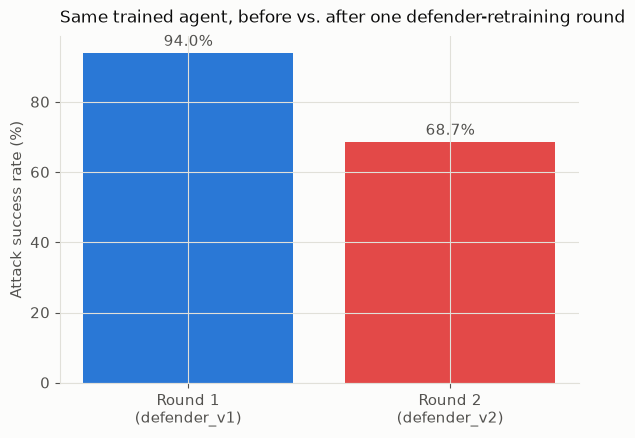

In [6]:

with open(f"{MODELS_DIR}/defender_v2_meta.json") as f:
    d2_meta = json.load(f)

print(f"Defender v2 training set added {d2_meta['n_adversarial_examples_added']} adversarial examples to the original 281 real positives")
print(f"Defender v2 holdout PR-AUC: {d2_meta['holdout_prauc']:.4f} (v1: {d1_meta['holdout_prauc']:.4f})")
print(f"Defender v2 holdout ROC-AUC: {d2_meta['holdout_rocauc']:.4f} (v1: {d1_meta['holdout_rocauc']:.4f})")
print()
print(f"SAME frozen agent vs. defender_v1: {summary['trained_policy_attack_success_rate']:.1%} attack success")
print(f"SAME frozen agent vs. defender_v2: {d2_meta['frozen_agent_attack_success_rate_vs_v2']:.1%} attack success")

fig, ax = plt.subplots(figsize=(6, 4.5))
rounds = ["Round 1\n(defender_v1)", "Round 2\n(defender_v2)"]
rates = [summary["trained_policy_attack_success_rate"] * 100, d2_meta["frozen_agent_attack_success_rate_vs_v2"] * 100]
bars = ax.bar(rounds, rates, color=[CATEGORICAL[0], CATEGORICAL[7]])
ax.set_ylabel("Attack success rate (%)")
ax.set_title("Same trained agent, before vs. after one defender-retraining round", color=INK, fontsize=12, loc="left", pad=10)
for bar, r in zip(bars, rates):
    ax.text(bar.get_x() + bar.get_width()/2, r + 2, f"{r:.1f}%", ha="center", color=INK_SECONDARY)
plt.tight_layout()
plt.show()


**Result: a real, substantial drop —
94.0% → 68.7%
attack success for the identical, frozen attacker — but a smaller one than
Al Hilal's 90.3% → 22.7%.** Two honest reasons, not one:

1. **`defender_v1` started from a much weaker baseline** (much higher
   random-policy success rate) — there was more ground to cover with the
   same single round of retraining.
2. **282 adversarial examples added to only 281 original positives is
   proportionally a much larger correction here** than Al Hilal's 337 added
   to 252 (roughly doubling Jordan's positive-label count vs. Al Hilal's
   ~1.3x) — yet the *result* moved less. That combination suggests Jordan's
   defender needs more than a single round, or a richer safe feature set,
   to close the gap the way Al Hilal's did in one step.

Unlike Al Hilal, `defender_v2`'s **real-holdout PR-AUC also improved**
(0.0168 → 0.0217, ROC-AUC held
roughly steady) — the retraining round didn't just patch the discovered
hole narrowly here, it measurably generalized better on the real data
too, a cleaner result than Al Hilal's slight ROC-AUC give-back.

## Step 8 — Red-team summary

| Finding | Detail |
|---|---|
| Undetected amount inflation is the *only* observed strategy | Random policy already wins 93.3% of the time; the trained agent found zero use for splitting across all 282 successful episodes |
| A weaker starting defender is beaten even more thoroughly | `defender_v1`'s PR-AUC (0.0168) is about half Al Hilal's (0.0339), and its random-baseline attack-success rate is correspondingly higher (93.3% vs. 86.0%) |
| One retraining round still helps, just not as much in one step | 94.0% → 68.7% attack success, with defender_v2's real-data PR-AUC genuinely improving too |
| Suggested patch | Same as Objective 1's own recommendation: this MVP's defender excludes `PEER_ZSCORE`/`AMOUNT_OVER_MEDIAN`; closing that gap (dynamic peer-group recomputation) is the most direct lever, same as Al Hilal's finding |

**Headline:** a second, independent dataset shows the same core pattern —
a fraud defender missing peer-group context is beaten by simple amount
inflation almost every time, learned or random, and a single round of
adversarial retraining measurably narrows that gap even when it doesn't
close it outright in one step.
